# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [33]:


import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [34]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')

users = pd.read_csv('/datasets/users_latam.csv')
usage =pd.read_csv('/datasets/usage.csv')


In [35]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [36]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [37]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [38]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [39]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [40]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [41]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [42]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [43]:

print(usage.isna().sum())
print(usage.isna().mean())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- users: city (11.7%), churn_date (88.35%)
usage: date (0.125%), duration (55.19%), length (44.74%)  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- en churn_date se ignora/elimina porque el alto porcentaje de nulos sugiere que esos clientes simplemente no se han dado de baja, no es un dato faltante por error
- en ciy se inviestiga para imputar o dejar como nulos
- date  suele ser un caso simple de imputación o dejar como nulos
- duration y length dejarlos como estan por que son nulos esperados ya que uno es llamadas y otros mensajes

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.
- en users 55 de 4000 registros (un poco más del 1%) tienen ese valor -999 en age, lo cual confirma que es un sentinel y no un dato faltante aleatorio.
- en duration(duration:75% = 6.99 max = 120.00) y length(length:75% = 64.00 max = 1490.00) noto un valor atípico u outlier enre el 75% y el max, en duration podría ser una llamada real que duró mucho, o podría ser un error y en lengt tambien podria ser lo mismo, tendremos una accion futura se investigará más adelante usando boxplots o reglas estadísticas (IQR) para confirmar si son outliers reales o errores
- Dado lo que acabamos de descubrir (el sentinel '?' en city), ese es un buen candidato natural entonces eso que notamos antes es un sentinel "?" que no se sabe de que ciudad son esos registros
- "la columna city tiene 96 registros (2.4%) con el valor '?', que también parece ser un sentinel".



El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [44]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [45]:
(users['age'] == -999).sum()

55

La columna user_id representa un identificador único para cada usuario. Por lo tanto, las estadísticas como la media, desviación estándar y percentiles no tienen una interpretación significativa, ya que los valores son identificadores y no cantidades numéricas que se puedan analizar matemáticamente.
La columna age presenta un valor mínimo de -999, lo cual es imposible para una edad humana y probablemente representa un dato faltante o un error de registro. El resto de los valores (25%, 50%, 75% y máximo) parecen estar dentro de un rango razonable. Se recomienda revisar y limpiar ese valor antes de realizar el análisis.

In [46]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas `id` y `user_id`, estas columnas son identificadores únicos, por lo que las estadísticas (mean, std, etc.) no son relevantes para detectar errores aquí

In [47]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].value_counts())

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Basico     2595
Premium    1405
Name: plan, dtype: int64


In [48]:
(users['city'] == '?').sum() / len(users) * 100

2.4


La columna city presenta 96 registros con el valor sentinel ? (2.4 % de los datos) que representan valores faltantes disfrazados, por lo que se reemplazaron por NaN para no distorsionar los análisis por ciudad.

La columna plan está completamente limpia y consistente, ya que únicamente contiene las dos categorías esperadas (Basico y Premium) sin errores de formato ni valores anómalos, por lo que no requiere limpieza.

In [49]:

# explorar columna categórica de usage
usage['type'].value_counts()


text    22092
call    17908
Name: type, dtype: int64

La columna type tiene text y call sin valores raros ni inconsistencias

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- El sentinel -999 en la columna age, el sentinel '?' en la columna city.
- ¿Qué acción tomarías? eliminar tanto los 96 registros con '?' en city como los 55 registros con -999 en age, ya que ambos representan porcentajes bajos (~2.4% y ~1.375%).  


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [50]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [51]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [52]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

La columna reg_date muestra que la mayoría de los registros corresponden a los años 2022 (1314), 2023 (1316) y 2024 (1330), los cuales son válidos porque coinciden con el periodo de datos del proyecto. Sin embargo, existen 40 registros correspondientes al año 2026, lo cual representa una inconsistencia, ya que el conjunto de datos únicamente contiene información hasta 2024. Estos registros podrían deberse a errores de captura o fechas incorrectas, por lo que es necesario revisarlos y corregirlos o eliminarlos antes del análisis.
La conclusión importante: 2022, 2023 y 2024 son años válidos; 2026 contiene registros inconsistentes.

In [53]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

In [54]:
usage['date'].isna().sum()

50


Qué año aparecen: solo 2024.
Por qué se mostró como decimal: porque hay valores NaT (nulos) en la columna, lo que obliga a que el tipo de dato sea float.
Cuántos NaT hay: 50.



✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- no no aparecen años imposibles
- ¿Qué harías con ellas?
- Registros con año 2026 en reg_date
Se recomienda revisar los 40 registros correspondientes al año 2026, ya que son inconsistentes con el periodo del proyecto, que llega hasta 2024. Si no es posible identificar la fecha correcta, se recomienda convertir esos valores en nulos (NA)
Valores NaT en usage['date']
Se recomienda revisar los 50 registros que contienen valores NaT, ya que representan únicamente el 0.125% del total de datos. Debido a que son una proporción muy pequeña, se pueden remplazar esos registros para evitar problemas en el análisis temporal, siempre que no contengan información importante en otras columnas.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [55]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [56]:
# Reemplazar ? por NA en city
users['city'] =users['city'].replace('?',pd.NA)
(users['city'] == '?').sum()


0

In [57]:
# Marcar fechas futuras como NA para reg_date
users.loc[ (users['reg_date'].dt.year == 2026) , 'reg_date'] = pd.NaT
(users['reg_date'].dt.year == 2026).sum()


0


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**

- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.
-   la ausencia de duration no es aleatoria, sino que depende completamente del valor de type. Eso confirma que es un patrón MAR (Missing At Random), porque la "razón" de los nulos se explica con otra columna observable.
-   Los valores nulos de la columna length corresponden exclusivamente a las llamadas telefónicas (type = 'call'), ya que estas no tienen una longitud de texto asociada. Se identifica un patrón MAR porque la ausencia de datos depende de una variable observable (type). Por lo tanto, se conservarán los valores nulos, ya que representan una condición natural de los datos y no un error de registro.
La decisión es conservar los valores nulos, porque son coherentes con la naturaleza de cada tipo de interacción.

Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

Los valores nulos de la columna duration corresponden exclusivamente a los mensajes de texto (type = 'text'), ya que estos no tienen una duración asociada. Se identifica un patrón MAR porque la ausencia de datos depende de una variable observable (type). Por lo tanto, se conservarán los valores nulos, ya que representan una condición natural de los datos y no un error de registro.



In [58]:
# Verificación MAR en usage (Missing At Random) para duration
usage[usage['duration'].isna()]['type'].value_counts()

text    22076
Name: type, dtype: int64

In [59]:
# Verificación MAR en usage (Missing At Random) para length
usage[usage['length'].isna()]['type'].value_counts()

call    17896
Name: type, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Se identificó que los valores nulos de duration corresponden exclusivamente a los registros con type = 'text', ya que los mensajes de texto no tienen una duración asociada. Por otro lado, los valores nulos de length corresponden a los registros con type = 'call', debido a que las llamadas no tienen una longitud de texto. Ambos casos presentan un patrón MAR (Missing At Random), porque la ausencia de datos depende de una variable observable (type). Por lo tanto, se decidió conservar los valores nulos, ya que representan una condición natural de los datos y no errores de registro.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [63]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(cantidad_mensajes = ('is_text', 'sum'),cantidad_llamadas = ('is_call', 'sum'),total_minutos = ('duration', 'sum')).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cantidad_mensajes,cantidad_llamadas,total_minutos
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [64]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cantidad_mensajes,cantidad_llamadas,total_minutos
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


In [68]:

user_profile = user_profile.rename(columns={'cantidad_mensajes': 'cant_mensajes', 'cantidad_llamadas': 'cant_llamadas','total_minutos': 'cant_minutos_llamada'})



user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01



### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.


In [65]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cantidad_mensajes,cantidad_llamadas,total_minutos
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.138285,5.524381,4.478120,23.317054
std,1154.898108,17.691541,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,4.000000,3.000000,11.120000
50%,12000.000000,48.000000,5.000000,4.000000,19.780000
75%,12999.500000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [67]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)

Basico     0.648662
Premium    0.351338
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

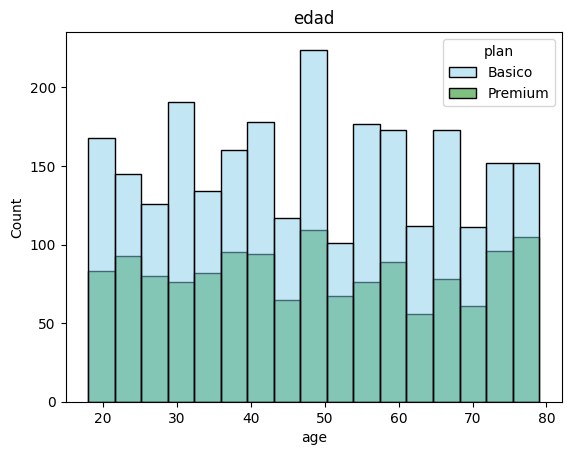

In [69]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.title('edad')
plt.show()

💡Insights: 
La distribución de edades muestra que tanto los usuarios del plan Básico como los del plan Premium se encuentran distribuidos en un rango aproximado de 18 a 80 años. El plan Básico presenta una mayor frecuencia de usuarios en la mayoría de los rangos de edad, aunque ambos planes muestran una distribución similar. No se observa una concentración clara en un rango específico ni una diferencia evidente en la distribución de edades entre ambos planes. La distribución es relativamente uniforme, aunque presenta algunas variaciones en las frecuencias, sin un sesgo marcado hacia la derecha o izquierda.

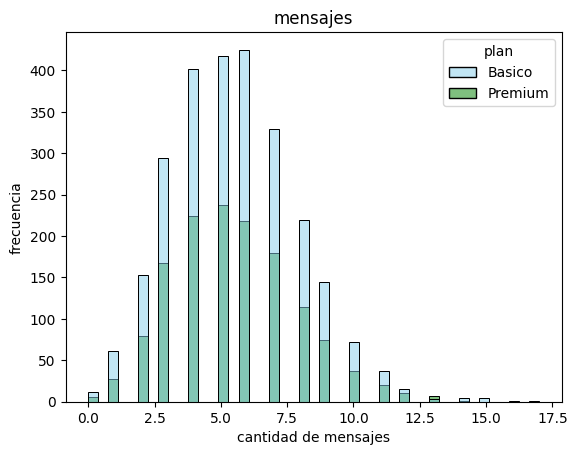

In [71]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.xlabel('cantidad de mensajes')
plt.ylabel('frecuencia')
plt.title('mensajes')
plt.show()


💡Insights: 
- Se observa que los usuarios de ambos planes concentran la mayor cantidad de mensajes enviados entre 3 y 7 mensajes, con una frecuencia máxima alrededor de 5 y 6 mensajes. Los usuarios del plan Básico presentan frecuencias absolutas más altas que los usuarios Premium, pero ambos planes muestran un comportamiento similar. La distribución está sesgada hacia la derecha, ya que la mayoría de los usuarios envía una cantidad moderada de mensajes y existe una menor frecuencia de usuarios que envían cantidades elevadas. No se observa un patrón de comportamiento claramente diferente entre ambos planes.

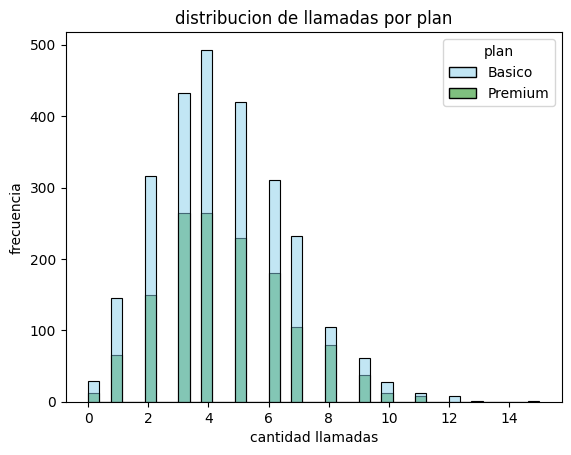

In [72]:

# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.xlabel('cantidad llamadas')
plt.ylabel('frecuencia')
plt.title('distribucion de llamadas por plan')
plt.show()


💡Insights: 
- Tipo de distribución: La distribución es sesgada a la derecha (asimétrica positiva), ya que la mayor concentración de usuarios se ubica entre las 2 y 5 llamadas, mientras que la cola se extiende hacia valores más altos (hasta 14-15 llamadas) con una frecuencia mucho menor.

Comportamiento por plan: Dentro del plan Básico hay una mayor cantidad total de usuarios (barras azules más altas), pero no existe una diferencia marcada en el patrón de comportamiento entre ambos planes. Tanto los usuarios del plan Básico como los del plan Premium tienden a realizar en promedio entre 3 y 5 llamadas (con el pico máximo en 4 llamadas), manteniendo proporciones muy similares a lo largo de todo el rango.

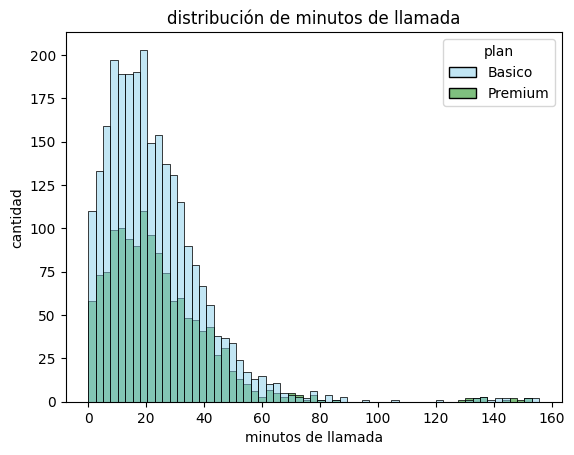

In [73]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.xlabel('minutos de llamada')
plt.ylabel('cantidad')
plt.title('distribución de minutos de llamada')
plt.show()

💡Insights: 
- Tipo de distribución: Presenta una clara distribución sesgada a la derecha (asimétrica positiva). La gran mayoría de las llamadas tienen una duración corta, concentrándose principalmente entre los 5 y 25 minutos (con el pico máximo alrededor de los 10 a 20 minutos), mientras que a partir de los 30 minutos la frecuencia cae progresivamente formando una cola larga hacia valores extremos (llegando hasta los 140-160 minutos).

Comportamiento por plan: Al igual que en el gráfico anterior, el plan Básico tiene un volumen total mayor de registros que el plan Premium, pero no existe algún patrón de consumo diferenciado según el plan. Tanto los usuarios Básico como los Premium tienden a realizar llamadas de duración muy similar (concentradas debajo de los 25-30 minutos) y presentan proporciones casi idénticas a lo largo de toda la gráfica.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

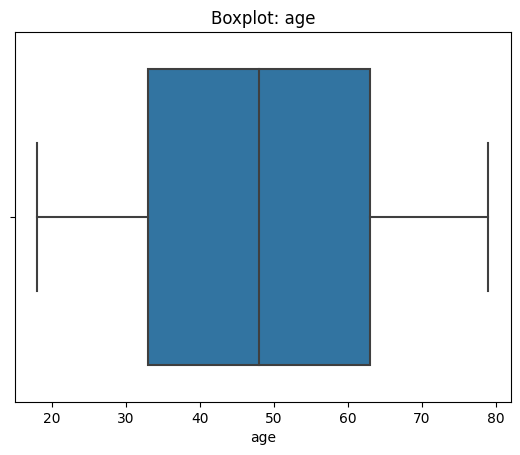

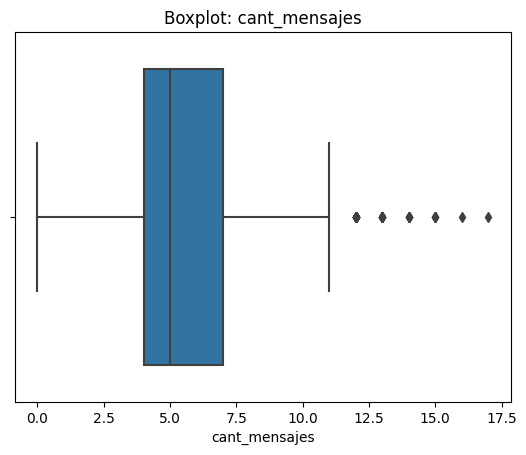

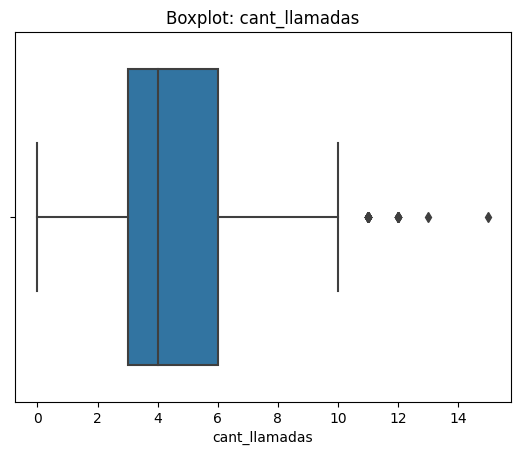

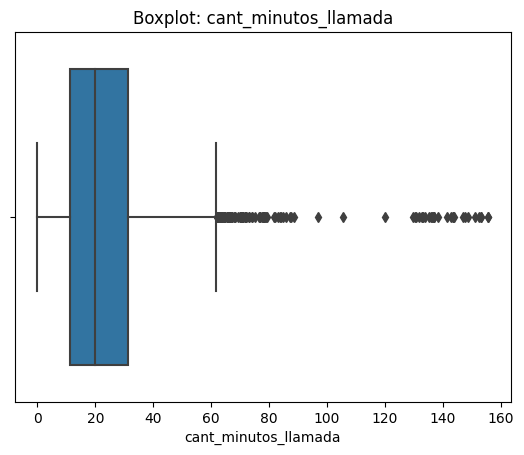

In [75]:
# Visualizando usando BoxPlot 
columnas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age:No existen outliers. Todos los valores se encuentran dentro de los bigotes del diagrama (aproximadamente entre 18 y 70 años), mostrando una distribución equilibrada.
cant_mensajes`:Sí existen outliers en el lado derecho (a partir de ~115 mensajes en adelante, llegando hasta ~175).
cant_llamadas:Sí existen outliers en el lado derecho(a partir de ~10 llamadas en adelante, llegando hasta 15).
cant_minutos_llamada:Sí existen outliers en el lado derecho** (a partir de ~60 minutos en adelante, llegando hasta ~160 minutos).
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [76]:
# Calcular límites con el método IQR

cols_con_outliers = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in cols_con_outliers:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    
    # Contamos cuántos usuarios superan ese límite
    outliers_count = (user_profile[col] > limite_superior).sum()
    
    print(f"Columna: {col}")
    print(f"  Límite superior (IQR): {limite_superior:.2f}")
    print(f"  Cantidad de outliers: {outliers_count}\n")

Columna: cant_mensajes
  Límite superior (IQR): 11.50
  Cantidad de outliers: 46

Columna: cant_llamadas
  Límite superior (IQR): 10.50
  Cantidad de outliers: 30

Columna: cant_minutos_llamada
  Límite superior (IQR): 61.86
  Cantidad de outliers: 109



In [78]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,23.317054
std,17.691541,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


Insights:cant_mensajes Mantener los outliers (46 usuarios por encima del límite superior de 11.50 mensajes, con un máximo de 17.0). Enviar entre 12 y 17 mensajes es un comportamiento completamente normal y realista para un usuario activo; no se trata de errores de captura, por lo que conservarlos mantiene la integridad del análisis.
cant_llamadas Mantener los outliers (30 usuarios por encima del límite superior de 10.50 llamadas, con un máximo de 15.0). Realizar entre 11 y 15 llamadas es un consumo plausible dentro de un servicio telefónico y representa a los clientes con mayor actividad.
cant_minutos_llamada Mantener los outliers (109 usuarios por encima del límite superior de 61.86 minutos, con un máximo de 155.69). Acumular hasta ~156 minutos corresponde a usuarios con alto consumo de voz (segmento de uso intensivo), no a valores atípicos erróneos, por lo que son clave para diseñar planes comerciales.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [80]:
# Crear columna grupo_uso
# Crear columna grupo_uso
def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    
    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [81]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [82]:
# Crear columna grupo_edad
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)
print(user_profile['grupo_edad'].value_counts())

Adulto          2017
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [83]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

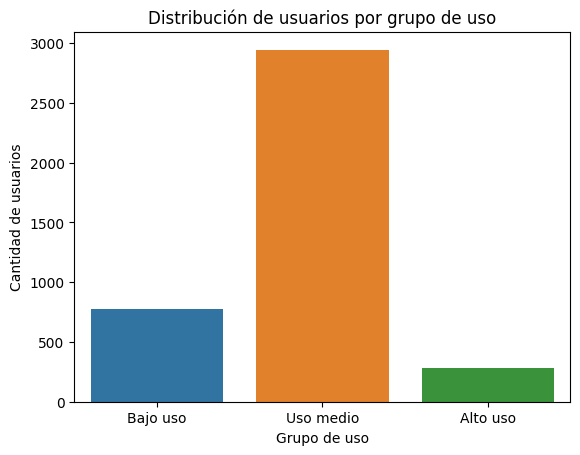

In [84]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

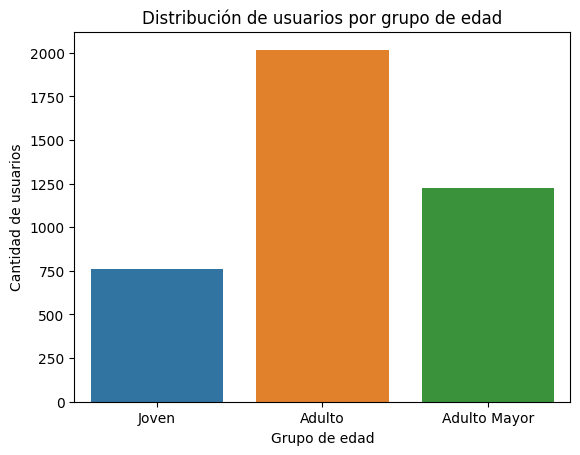

In [85]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En la tabla users se detectaron errores de captura: 96 registros con ? en city (2.4%), 55 registros con el valor centinela -999 en age (1.4%) y 40 registros con año imposible 2026 en reg_date (1%).
- En la tabla usage se encontraron 50 valores nulos en date (0.125%). Los demás nulos son esperados por la lógica del negocio: 3,534 en churn_date (88.35% de clientes activos), 22,076 en duration (55.19% correspondientes a mensajes) y 17,896 en length (44.74% correspondientes a llamadas).


🔍 **Segmentos por Edad**
- Predomina el grupo Adulto (30 a 59 años) con 2,017 usuarios (50.4% del total), seguido por Adulto Mayor (60+ años) con 1,222 usuarios (30.6%) y Joven (menores de 30 años) con 760 usuarios (19.0%).
- Más del 80% de la cartera de clientes de ConnectaTel tiene 30 años o más, lo que define una base demográfica madura.


📊 **Segmentos por Nivel de Uso**
- Los usuarios se dividieron en Bajo uso (menos de 5 llamadas y 5 mensajes), Uso medio (menos de 10 llamadas y 10 mensajes) y Alto uso (10 o más llamadas o mensajes).
- Se identificaron valores atípicos (outliers) en el extremo superior: 46 usuarios superan 11.50 mensajes (máx 17), 30 usuarios superan 10.50 llamadas (máx 15) y 109 usuarios superan 61.86 minutos (máx 155.69), los cuales se conservaron porque representan clientes reales de consumo intensivo.


➡️ Esto sugiere que los segmentos más valiosos para ConnectaTel son los Adultos (30–59 años) con Alto uso por representar la mayor masa crítica de ingresos recurrentes, junto con los usuarios de Alto uso suscritos al plan Básico que ya superan los límites de 100 minutos incluidos y tienen alto potencial de migración.


💡 **Recomendaciones**
- Lanzar campañas de upselling del plan Básico al plan Premium dirigidas a los usuarios detectados con consumos superiores a 100 minutos de llamada, destacando el ahorro frente a cargos por excedentes.
- Crear un plan intermedio (Plan Plus) con alrededor de 250 minutos y 200 mensajes para capturar a los clientes de Uso medio y Alto uso que exceden el plan Básico pero no requieren los 600 minutos del plan Premium, reforzando beneficios de voz para el público mayor de 30 años.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

https://github.com/yakuza333999/sprint7-final-project.git